# Program Assignment 3: Deep Reinforcement Learning

In [1]:
import tensorflow as tf
import numpy as np
from dataclasses import dataclass
from collections import deque
import random
import matplotlib.pyplot as plt
import pygame

I0000 00:00:1775257364.979957  107040 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1775257365.015043  107040 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1775257366.105111  107040 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


pygame 2.6.1 (SDL 2.28.4, Python 3.12.13)
Hello from the pygame community. https://www.pygame.org/contribute.html


In [2]:
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Setup the environment & Define reward funciton

I set up gymnasium-like environment

In [3]:
@dataclass
class VacuumEnvCfg:
    step_penalty = -0.1
    wall_hit_penalty = -1.0
    clean_reward = 20.0
    end_reward = 200.0

class VacuumEnv:
    ACTIONS = {0: (-1, 0), 1: (1, 0), 2: (0, 1), 3: (0, -1)}
    ACTION_NAMES = {0: "N", 1: "S", 2: "E", 3: "W"}
    NUM_ACTIONS = 4

    def __init__(self, rows=5, cols=5, num_dirty=3, max_steps=2000, dirty_positions=None):
        self.rows = rows
        self.cols = cols
        self.num_dirty = num_dirty
        self.max_steps = max_steps
        self.dirty_positions = dirty_positions  # e.g. [(1,2), (3,4), (0,3)]

        self.agent_pos = None
        self.dirty_grid = None
        self.steps = 0
        self.total_dirty = 0
        self.cleaned = 0

    def reset(self):
        self.agent_pos = [0, 0]
        self.dirty_grid = np.zeros((self.rows, self.cols), dtype=np.float32)
        self.steps = 0
        self.cleaned = 0

        if self.dirty_positions is not None:
            for r, c in self.dirty_positions:
                self.dirty_grid[r][c] = 1.0
            self.total_dirty = len(self.dirty_positions)
        else:
            candidates = [(r, c) for r in range(self.rows) for c in range(self.cols) if (r, c) != (0, 0)]
            chosen = np.random.choice(len(candidates), size=min(self.num_dirty, len(candidates)), replace=False)
            for idx in chosen:
                r, c = candidates[idx]
                self.dirty_grid[r][c] = 1.0
            self.total_dirty = len(chosen)

        return self._get_state()

    def _get_state(self):
        # Channel 0: agent position (one-hot grid)
        # Channel 1: dirty tiles
        state = np.zeros((self.rows, self.cols, 2), dtype=np.float32)
        state[self.agent_pos[0], self.agent_pos[1], 0] = 1.0
        state[:, :, 1] = self.dirty_grid
        return state

    @property
    def state_shape(self):
        return (self.rows, self.cols, 2)

    def step(self, action):
        self.steps += 1
        dr, dc = self.ACTIONS[action]
        new_r = self.agent_pos[0] + dr
        new_c = self.agent_pos[1] + dc

        reward = VacuumEnvCfg.step_penalty

        if new_r < 0 or new_r >= self.rows or new_c < 0 or new_c >= self.cols:
            reward = VacuumEnvCfg.wall_hit_penalty
        else:
            self.agent_pos = [new_r, new_c]

            if self.dirty_grid[new_r][new_c] == 1.0:
                self.dirty_grid[new_r][new_c] = 0.0
                self.cleaned += 1
                reward = VacuumEnvCfg.clean_reward

        terminated = False
        truncated = False
        remaining = int(self.dirty_grid.sum())

        if remaining == 0:
            terminated = True
            reward += VacuumEnvCfg.end_reward

        if self.steps >= self.max_steps:
            truncated = True

        info = {
            "steps": self.steps,
            "cleaned": self.cleaned,
            "remaining": remaining,
        }

        return self._get_state(), reward, terminated, truncated, info

# Define model

In [ ]:
class ReplayBuffer:

    def __init__(self):
        self.buffer = deque(maxlen=500000)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (
            np.array(states, dtype=np.float32),
            np.array(actions, dtype=np.int32),
            np.array(rewards, dtype=np.float32),
            np.array(next_states, dtype=np.float32),
            np.array(dones, dtype=np.float32),
        )

    def __len__(self):
        return len(self.buffer)


class DQNAgent:
    def __init__(
        self,
        state_shape,
        action_size=4,
        lr=1e-4,
        gamma=0.99,
        epsilon_start=1.0,
        epsilon_end=0.01,
        epsilon_decay=0.999,
        batch_size=64,
        tau=0.005,
    ):
        self.state_shape = state_shape
        self.action_size = action_size
        self.gamma = gamma
        self.epsilon = epsilon_start
        self.epsilon_end = epsilon_end
        self.epsilon_decay = epsilon_decay
        self.batch_size = batch_size
        self.tau = tau

        self.replay_buffer = ReplayBuffer()

        self.optimizer = tf.keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0)

        # Double DQN
        self.online_net = self._build_network()
        self.target_net = self._build_network()
        self.update_target_network()

        self.train_step_count = 0

        # Build the tf.function training step
        self._train_step = tf.function(self._train_step_impl)

    def _build_network(self):
        inputs = tf.keras.layers.Input(shape=self.state_shape)

        # CNN to extract spatial features
        x = tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu")(inputs)
        x = tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu")(x)
        x = tf.keras.layers.Conv2D(256, 3, padding="same", activation="relu")(x)
        x = tf.keras.layers.Flatten()(x)
        x = tf.keras.layers.Dense(256, activation="relu")(x)
        x = tf.keras.layers.Dense(128, activation="relu")(x)
        outputs = tf.keras.layers.Dense(self.action_size, activation="linear")(x)

        return tf.keras.Model(inputs=inputs, outputs=outputs)

    def update_target_network(self):
        self.target_net.set_weights(self.online_net.get_weights())

    def soft_update_target(self):
        for target_var, online_var in zip(self.target_net.trainable_variables,
                                           self.online_net.trainable_variables):
            target_var.assign(self.tau * online_var + (1.0 - self.tau) * target_var)

    def select_action(self, state, greedy=False):
        if not greedy and np.random.rand() < self.epsilon:
            return np.random.randint(self.action_size)
        q_values = self.online_net(state[np.newaxis], training=False).numpy()
        return int(np.argmax(q_values[0]))

    def store(self, state, action, reward, next_state, done):
        self.replay_buffer.push(state, action, reward, next_state, done)

    def _train_step_impl(self, states, actions, rewards, next_states, dones):
        # Double DQN target computation
        next_q_online = self.online_net(next_states, training=False)
        best_actions = tf.argmax(next_q_online, axis=1, output_type=tf.int32)

        next_q_target = self.target_net(next_states, training=False)
        best_next_q = tf.reduce_sum(
            next_q_target * tf.one_hot(best_actions, self.action_size), axis=1
        )
        target_q = rewards + self.gamma * best_next_q * (1.0 - dones)

        with tf.GradientTape() as tape:
            q_values = self.online_net(states, training=True)
            q_action = tf.reduce_sum(
                q_values * tf.one_hot(actions, self.action_size), axis=1
            )
            loss = tf.reduce_mean(tf.keras.losses.huber(target_q, q_action))

        grads = tape.gradient(loss, self.online_net.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.online_net.trainable_variables))
        return loss

    def train(self):
        if len(self.replay_buffer) < 1000:
            return None

        states, actions, rewards, next_states, dones = self.replay_buffer.sample(self.batch_size)

        loss = self._train_step(
            tf.constant(states),
            tf.constant(actions),
            tf.constant(rewards),
            tf.constant(next_states),
            tf.constant(dones),
        )

        self.train_step_count += 1

        # Soft update target network every training step
        self.soft_update_target()

        return loss.numpy()

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_end, self.epsilon * self.epsilon_decay)

    def save(self, path="dqn_model.keras"):
        self.online_net.save(path)

    def load(self, path="dqn_model.keras"):
        self.online_net = tf.keras.models.load_model(path)
        self.update_target_network()


## Train it

Make Train Block

In [5]:
def train(
    rows=5,
    cols=5,
    num_dirty=3,
    num_episodes=200,
    max_steps=100,
    batch_size=512,
    train_every=4,
    patience=10,
    dirty_positions=None,
):

    env = VacuumEnv(rows=rows, cols=cols, num_dirty=num_dirty, max_steps=max_steps, dirty_positions=dirty_positions)

    agent = DQNAgent(
        state_shape=env.state_shape,
        action_size=VacuumEnv.NUM_ACTIONS,
        batch_size=batch_size,
    )

    episode_rewards = []
    episode_steps = []
    episode_cleaned = []
    losses = []
    step_count = 0
    best_avg_reward = -float("inf")
    no_improve_count = 0
    save_path = f"dqn_{rows}x{cols}.keras"

    for ep in range(1, num_episodes + 1):
        state = env.reset()
        total_reward = 0.0

        while True:
            action = agent.select_action(state)
            next_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            agent.store(state, action, reward, next_state, terminated)

            step_count += 1
            if step_count % train_every == 0:
                loss = agent.train()
                if loss is not None:
                    losses.append(loss)


            state = next_state
            total_reward += reward

            if done:
                break

        agent.decay_epsilon()

        episode_rewards.append(total_reward)
        episode_steps.append(info["steps"])
        episode_cleaned.append(info["cleaned"])

        if ep % 50 == 0:
            avg_r = np.mean(episode_rewards[-50:])
            avg_s = np.mean(episode_steps[-50:])
            avg_c = np.mean(episode_cleaned[-50:])

            if avg_r > best_avg_reward:
                best_avg_reward = avg_r
                no_improve_count = 0
                agent.save(save_path)
            else:
                no_improve_count += 1

            print(
                f"Ep {ep} | AvgR: {avg_r:.1f} | AvgS: {avg_s:.1f} | ",
                f"Clean: {avg_c:.1f}/{env.total_dirty} | Eps: {agent.epsilon:.4f} | NoImprove: {no_improve_count}/{patience}"
            )

            if no_improve_count >= patience:
                print(f"Early stopping at episode {ep}: no improvement for {patience * 50} episodes.")
                break


    plot_training(episode_rewards, episode_steps, episode_cleaned, losses, (rows, cols))

    agent.load(save_path)
    return agent, env


def plot_training(rewards, steps, cleaned, losses, size):

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    axes[0, 0].plot(rewards)
    axes[0, 0].set_title("Episode Reward")
    axes[0, 0].set_xlabel("Episode")

    axes[0, 1].plot(steps)
    axes[0, 1].set_title("Steps per Episode")
    axes[0, 1].set_xlabel("Episode")

    axes[1, 0].plot(cleaned)
    axes[1, 0].set_title("Tiles Cleaned per Episode")
    axes[1, 0].set_xlabel("Episode")

    axes[1, 1].plot(losses)
    axes[1, 1].set_title("Training Loss")
    axes[1, 1].set_xlabel("Training Step")

    plt.tight_layout()
    plt.savefig(f"training_curves({size[0]}x{size[1]}).png", dpi=150)
    plt.show()

### Train 5x5 Environment

Training on 5x5 environment...


I0000 00:00:1775257367.005102  107040 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6133 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9
I0000 00:00:1775257367.744422  107040 cuda_dnn.cc:461] Loaded cuDNN version 92000


Ep 50 | AvgR: 144.6 | AvgS: 77.6 |  Clean: 2.5/3 | Eps: 0.9512 | NoImprove: 0/10
Ep 100 | AvgR: 185.1 | AvgS: 64.3 |  Clean: 2.7/3 | Eps: 0.9048 | NoImprove: 0/10
Ep 150 | AvgR: 229.8 | AvgS: 51.1 |  Clean: 2.9/3 | Eps: 0.8606 | NoImprove: 0/10
Ep 200 | AvgR: 232.3 | AvgS: 45.5 |  Clean: 2.9/3 | Eps: 0.8186 | NoImprove: 0/10
Ep 250 | AvgR: 250.8 | AvgS: 42.4 |  Clean: 3.0/3 | Eps: 0.7787 | NoImprove: 0/10
Ep 300 | AvgR: 252.9 | AvgS: 34.3 |  Clean: 3.0/3 | Eps: 0.7407 | NoImprove: 0/10
Ep 350 | AvgR: 253.3 | AvgS: 31.7 |  Clean: 3.0/3 | Eps: 0.7046 | NoImprove: 0/10
Ep 400 | AvgR: 255.0 | AvgS: 28.6 |  Clean: 3.0/3 | Eps: 0.6702 | NoImprove: 0/10
Ep 450 | AvgR: 255.3 | AvgS: 25.7 |  Clean: 3.0/3 | Eps: 0.6375 | NoImprove: 0/10
Ep 500 | AvgR: 250.5 | AvgS: 28.0 |  Clean: 3.0/3 | Eps: 0.6064 | NoImprove: 1/10
Ep 550 | AvgR: 247.8 | AvgS: 33.6 |  Clean: 3.0/3 | Eps: 0.5768 | NoImprove: 2/10
Ep 600 | AvgR: 256.7 | AvgS: 20.1 |  Clean: 3.0/3 | Eps: 0.5486 | NoImprove: 0/10
Ep 650 | AvgR: 25

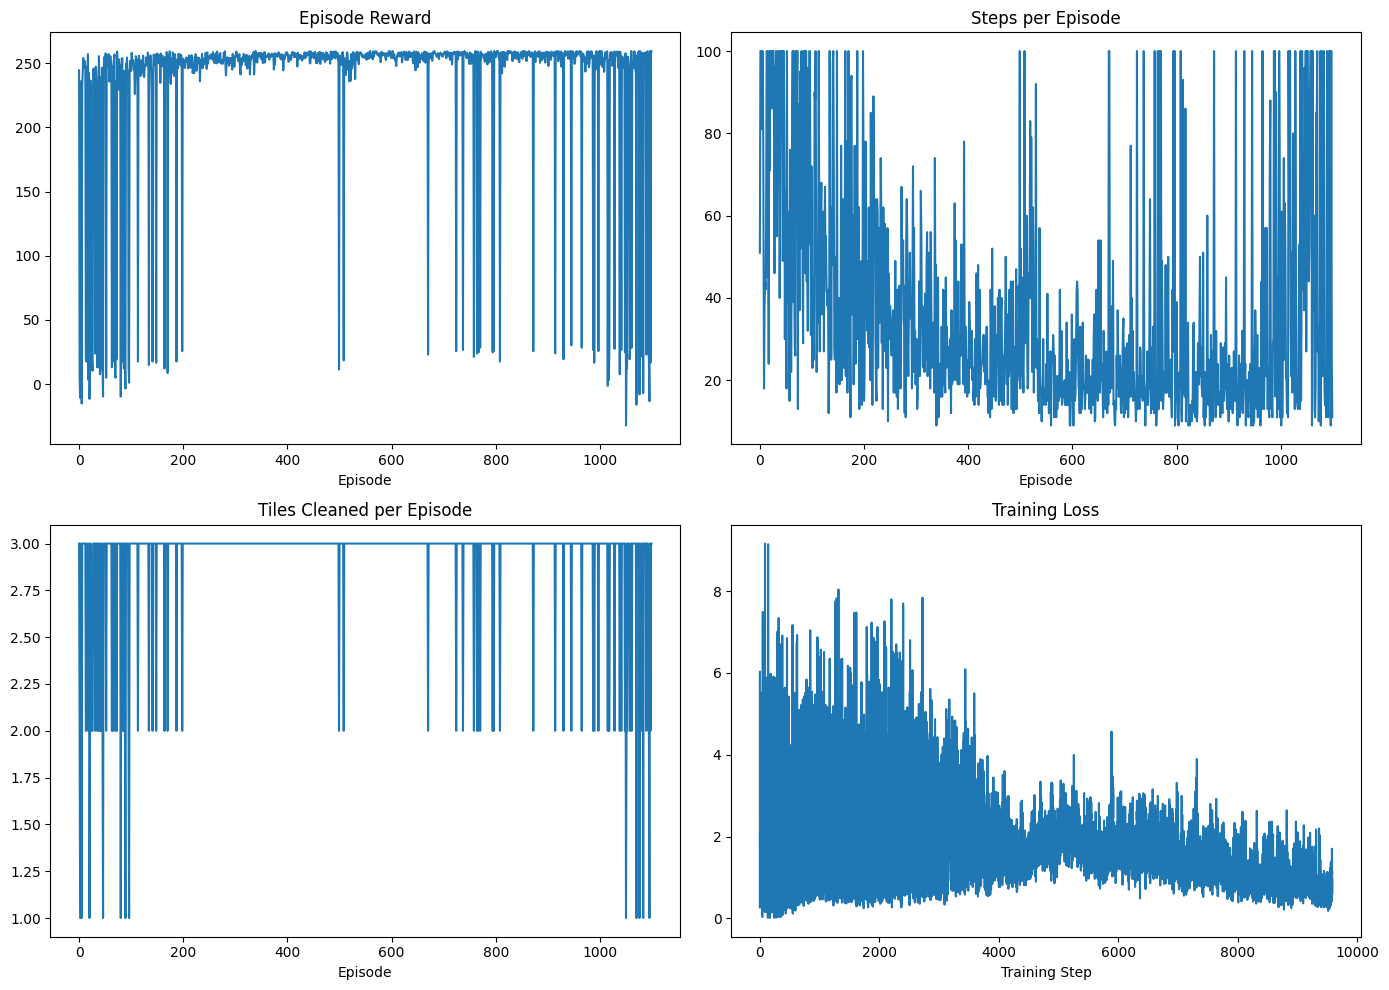

In [ ]:
print("Training on 5x5 environment...")
dirty_positions_5x5 = [(1, 2), (3, 4), (0, 3)]
agent_5, env_5 = train(
    rows=5, cols=5, num_dirty=3,
    dirty_positions=dirty_positions_5x5,
    num_episodes=2000,12
    max_steps=100,
    batch_size=128,
)


### Train 10x10 Environment


Training on 10x10...
Ep 50 | AvgR: 233.0 | AvgS: 305.1 |  Clean: 5.0/5 | Eps: 0.9512 | NoImprove: 0/10
Ep 100 | AvgR: 271.3 | AvgS: 160.5 |  Clean: 5.0/5 | Eps: 0.9048 | NoImprove: 0/10
Ep 150 | AvgR: 278.5 | AvgS: 131.2 |  Clean: 5.0/5 | Eps: 0.8606 | NoImprove: 0/10
Ep 200 | AvgR: 281.2 | AvgS: 109.8 |  Clean: 5.0/5 | Eps: 0.8186 | NoImprove: 0/10
Ep 250 | AvgR: 274.1 | AvgS: 155.3 |  Clean: 5.0/5 | Eps: 0.7787 | NoImprove: 1/10
Ep 300 | AvgR: 240.9 | AvgS: 238.9 |  Clean: 4.9/5 | Eps: 0.7407 | NoImprove: 2/10
Ep 350 | AvgR: 265.5 | AvgS: 190.0 |  Clean: 5.0/5 | Eps: 0.7046 | NoImprove: 3/10
Ep 400 | AvgR: 265.8 | AvgS: 172.9 |  Clean: 5.0/5 | Eps: 0.6702 | NoImprove: 4/10
Ep 450 | AvgR: 273.3 | AvgS: 164.6 |  Clean: 5.0/5 | Eps: 0.6375 | NoImprove: 5/10
Ep 500 | AvgR: 283.7 | AvgS: 101.6 |  Clean: 5.0/5 | Eps: 0.6064 | NoImprove: 0/10
Ep 550 | AvgR: 292.6 | AvgS: 50.9 |  Clean: 5.0/5 | Eps: 0.5768 | NoImprove: 0/10
Ep 600 | AvgR: 294.6 | AvgS: 41.1 |  Clean: 5.0/5 | Eps: 0.5486 | N

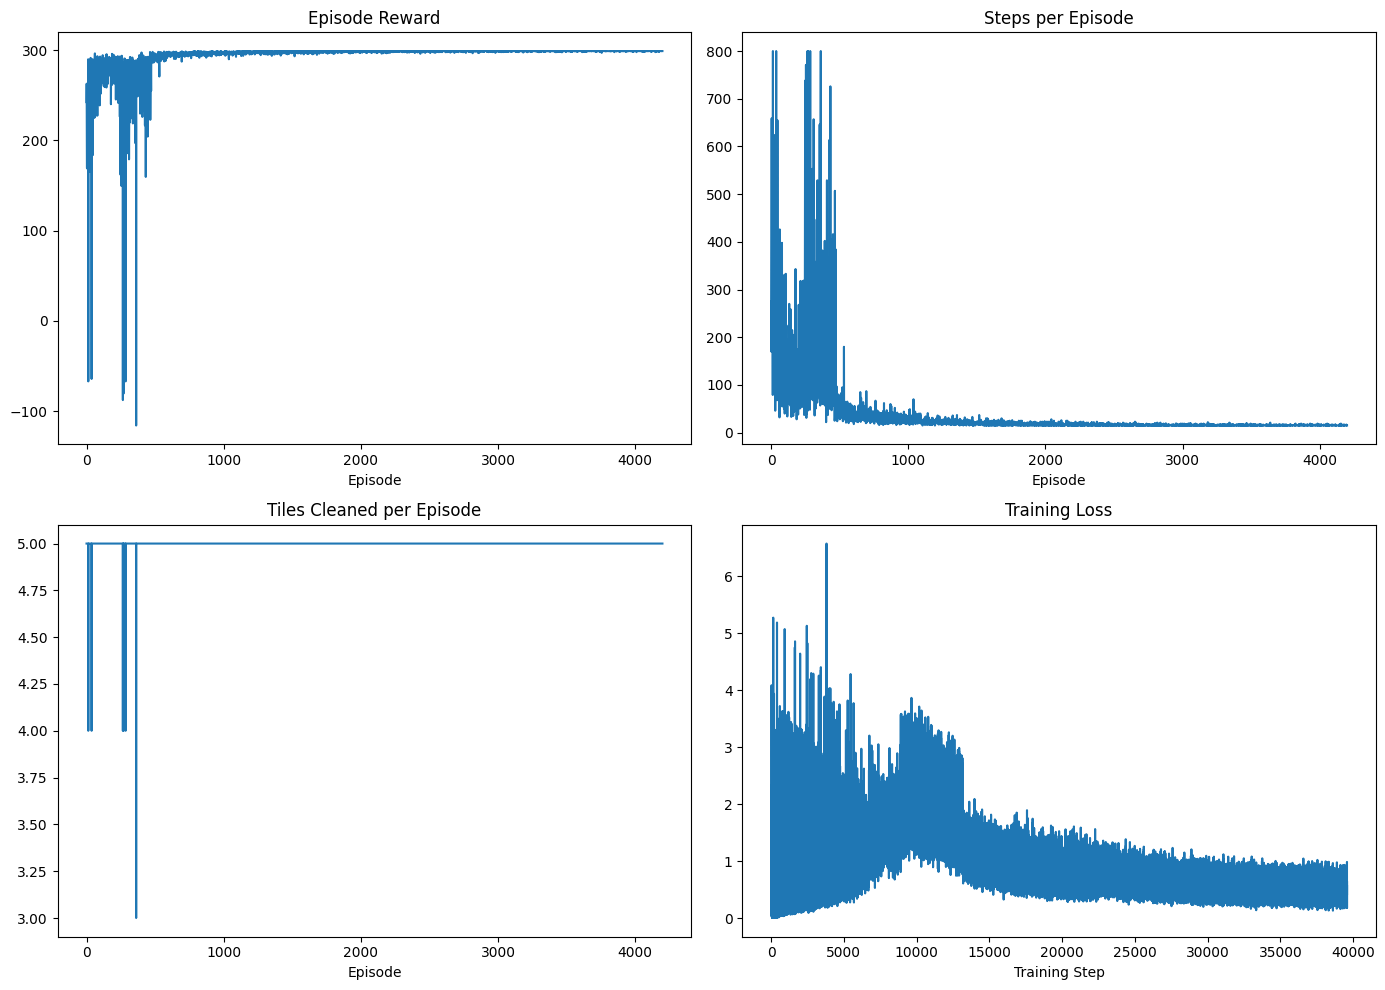

1

In [7]:
print("\nTraining on 10x10...")
dirty_positions_10x10 = [(1, 2), (3, 4), (0, 3), (2, 1), (4, 0)]
agent_10, env_10 = train(rows=10, cols=10, num_dirty=10, dirty_positions=dirty_positions_10x10, batch_size=128,
                         num_episodes=5000, max_steps=800, train_every=4)


Training on 15x15...
Ep 50 | AvgR: 84.4 | AvgS: 829.7 |  Clean: 8.0/10 | Eps: 0.9512 | NoImprove: 0/10
Ep 100 | AvgR: 216.3 | AvgS: 723.3 |  Clean: 9.4/10 | Eps: 0.9048 | NoImprove: 0/10
Ep 150 | AvgR: 277.7 | AvgS: 585.3 |  Clean: 9.8/10 | Eps: 0.8606 | NoImprove: 0/10
Ep 200 | AvgR: 323.3 | AvgS: 412.4 |  Clean: 9.9/10 | Eps: 0.8186 | NoImprove: 0/10
Ep 250 | AvgR: 363.2 | AvgS: 267.5 |  Clean: 10.0/10 | Eps: 0.7787 | NoImprove: 0/10
Ep 300 | AvgR: 367.6 | AvgS: 241.5 |  Clean: 10.0/10 | Eps: 0.7407 | NoImprove: 0/10
Ep 350 | AvgR: 366.3 | AvgS: 253.4 |  Clean: 10.0/10 | Eps: 0.7046 | NoImprove: 1/10
Ep 400 | AvgR: 362.6 | AvgS: 219.6 |  Clean: 9.9/10 | Eps: 0.6702 | NoImprove: 2/10
Ep 450 | AvgR: 374.5 | AvgS: 192.8 |  Clean: 10.0/10 | Eps: 0.6375 | NoImprove: 0/10
Ep 500 | AvgR: 381.1 | AvgS: 152.5 |  Clean: 10.0/10 | Eps: 0.6064 | NoImprove: 0/10
Ep 550 | AvgR: 372.4 | AvgS: 188.2 |  Clean: 9.9/10 | Eps: 0.5768 | NoImprove: 1/10
Ep 600 | AvgR: 379.5 | AvgS: 167.3 |  Clean: 10.0/1

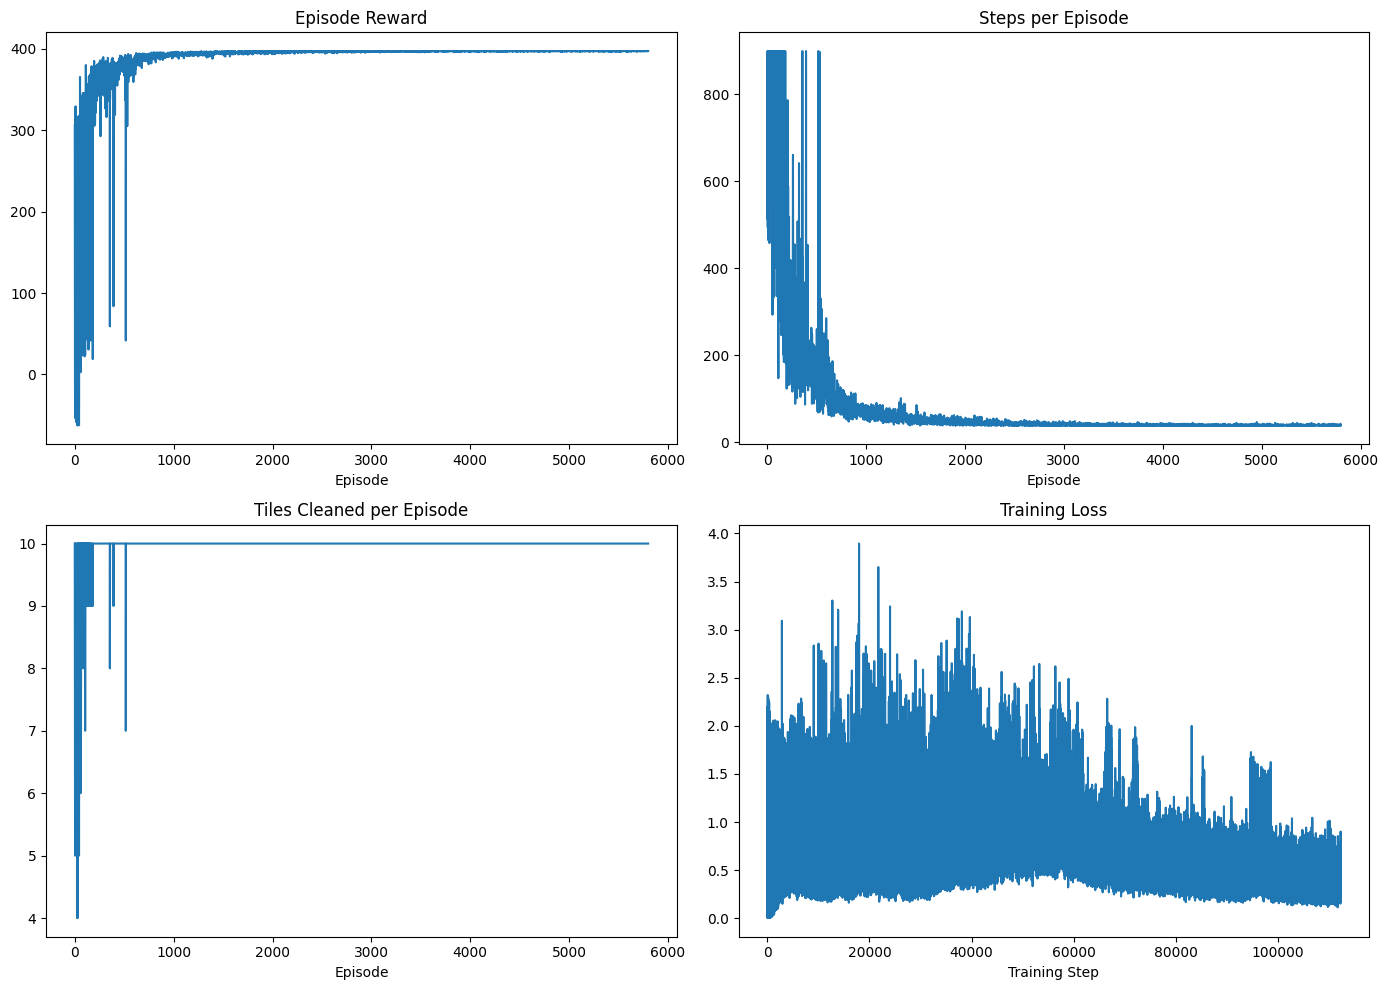

In [8]:
print("\nTraining on 15x15...")
dirty_positions_15x15 = [(1, 2), (3, 4), (0, 3), (2, 1), (4, 0),
                         (10, 10), (12, 13), (14, 14), (11, 11), (13, 12)]
agent_15, env_15 = train(rows=15, cols=15, num_dirty=10, dirty_positions=dirty_positions_15x15, batch_size=128,
                         num_episodes=10000, max_steps=900, train_every=4)


In [ ]:

WHITE = (255, 255, 255)
BLACK = (0, 0, 0)
GRAY = (200, 200, 200)
BROWN = (139, 90, 43)
GREEN = (60, 179, 113)
BLUE = (65, 105, 225)
RED = (220, 60, 60)

CELL_SIZE = 60
FPS = 5 # Frame rate for visualization (lower is easier to observe)


def run_pygame(agent, env):

    rows, cols = env.rows, env.cols
    width = cols * CELL_SIZE
    height = rows * CELL_SIZE + 80  # gap for info display

    pygame.init()
    screen = pygame.display.set_mode((width, height))
    pygame.display.set_caption("Vacuum Cleaner DQN")
    clock = pygame.time.Clock()
    font = pygame.font.SysFont("monospace", 20)

    state = env.reset()
    done = False
    total_reward = 0.0
    action_name = ""
    trail = set()  # path history for visualization

    while True:
        # act
        if not done:
            action = agent.select_action(state, greedy=True)
            action_name = VacuumEnv.ACTION_NAMES[action]
            state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            total_reward += reward
            trail.add(tuple(env.agent_pos))

        # drawing
        screen.fill(WHITE)

        for r in range(rows):
            for c in range(cols):
                rect = pygame.Rect(c * CELL_SIZE, r * CELL_SIZE, CELL_SIZE, CELL_SIZE)

                # background color
                if env.dirty_grid[r][c] == 1.0:
                    pygame.draw.rect(screen, BROWN, rect)  # dirty tile
                elif (r, c) in trail:
                    pygame.draw.rect(screen, GREEN, rect)  # path
                else:
                    pygame.draw.rect(screen, WHITE, rect)

                # lines
                pygame.draw.rect(screen, GRAY, rect, 1)

        ar, ac = env.agent_pos
        center = (ac * CELL_SIZE + CELL_SIZE // 2, ar * CELL_SIZE + CELL_SIZE // 2)
        pygame.draw.circle(screen, BLUE, center, CELL_SIZE // 3)

        for r in range(rows):
            for c in range(cols):
                if env.dirty_grid[r][c] == 1.0:
                    cx = c * CELL_SIZE + CELL_SIZE // 2
                    cy = r * CELL_SIZE + CELL_SIZE // 2
                    txt = font.render("X", True, WHITE)
                    screen.blit(txt, (cx - 6, cy - 10))

        # information display
        y_info = rows * CELL_SIZE + 10
        info_text = f"Step:{env.steps}  Reward:{total_reward:.0f}  Action:{action_name}  Cleaned:{env.cleaned}/{env.total_dirty}"
        screen.blit(font.render(info_text, True, BLACK), (10, y_info))

        pygame.display.flip()
        clock.tick(FPS)


ROWS, COLS = 15, 15

env = VacuumEnv(rows=ROWS, cols=COLS, num_dirty=3, max_steps=100, dirty_positions=dirty_positions_15x15)

agent = DQNAgent(state_shape=env.state_shape)


agent.load(f"dqn_{ROWS}x{COLS}.keras")
print("Loaded trained model")


run_pygame(agent, env)

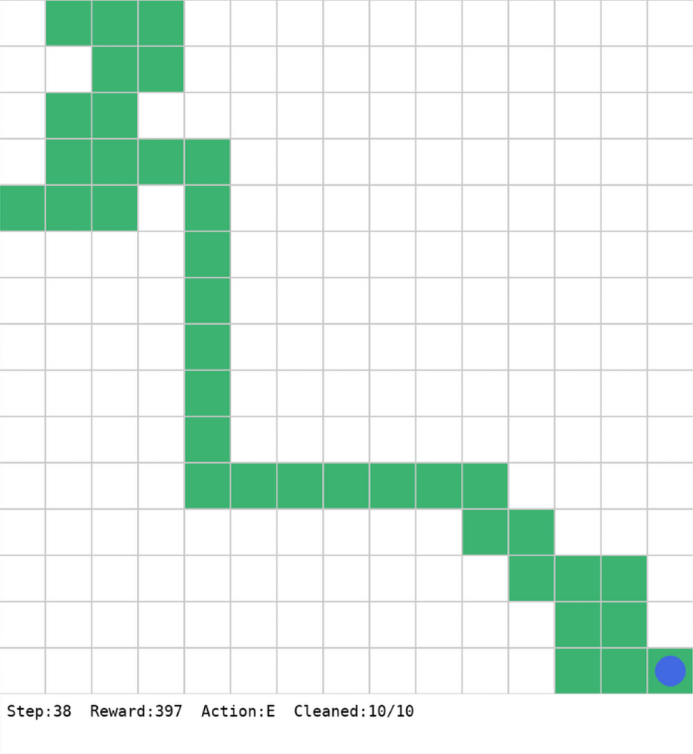

# Conclusion

In this programming assignment, we experimented with training an agent to learn how to clean a grid using Reinforcement Learning, specifically Q-Learning. We confirmed that as the dimensionality increases, the difficulty rises sharply, making learning considerably harder. In a fixed environment, the model finds a reasonably optimal path by settling on fixed Q-values; however, we also attempted dynamic learning, where the model struggled significantly. While it managed to succeed in learning for other configurations, it had notable difficulty with the 15×15 grid. We confirmed that much more time and proper reward tuning would be necessary for successful learning, but due to time constraints, we decided to settle for learning with fixed positions. The reason the agent is unnecessarily over-specced is precisely a remnant of our attempts to learn dynamic positions. In any case, from a graph perspective, we found something noteworthy in the 5×5 case: the model appears to learn stably in the early stages, but then suddenly becomes unstable later on. We believe one of the reasons for this is overfitting caused by a model that is over-specced relative to the grid size.